# Scaling FFA School with OPALX

Work through three machines in order: the **16-cell ring at 12 MeV**, its
**55° spiral / D-off variant**, and a **fourfold ring at 3 MeV**.
For each machine, inspect its input, predict the behavior, find the closed orbit
and full tunes, then track small displacements and interpret the plots.

OPALX performs the orbit and tune calculations using native `COF`.
Python prepares a fresh run, reads native results, and plots them.
The numerical settings come from **each machine's own `.in` file**.

Use Python 3.10+ with NumPy, pandas, Matplotlib, h5py and Jupyter, and an OPALX
build with native scaling-FFA COF and full-tune support. Set `OPALX_EXE` before
starting Jupyter or set `EXECUTABLE` below. On this Mac, for example:

```sh
export OPALX_EXE="$HOME/git/opalx/build_openmp/bin/opalx"
```

Open from either `FFA25-school` or `FFA25-school/opalx` and run from the top.
Start a new session by restarting the kernel and running all cells; generated
results are never silently reused. The default uses one process and one OpenMP
thread. No MPI launcher is required. For a system that needs one, set
`OPALX_LAUNCHER='mpiexec -n 1'` before starting Jupyter.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os
import sys
import uuid

# Locate the course from the notebook directory or the repository root.
START = Path.cwd().resolve()
COURSE = next((p for base in (START, *START.parents)
               for p in (base, base / "opalx")
               if (p / "pyfiles" / "school.py").is_file()), None)
if COURSE is None:
    raise RuntimeError("Open this notebook inside FFA25-school or FFA25-school/opalx.")
CACHE = COURSE / "runs" / ".cache"
CACHE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE))
sys.path.insert(0, str(COURSE / "pyfiles"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
import school

%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 180})

EXECUTABLE = None  # Otherwise use OPALX_EXE or opalx on PATH.
EXE = school.find_executable(EXECUTABLE)
SESSION = COURSE / "runs" / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8])
SESSION.mkdir(parents=True, exist_ok=False)
DISPLACEMENT = 1e-3  # Metres; amplitude of the later tracking experiment.
cof_paths, cof_results, track_paths, trajectories = {}, {}, {}, {}

print("OPALX:", EXE)
print("Fresh session:", SESSION)

Matplotlib is building the font cache; this may take a moment.


OPALX: /Users/adelmann/git/opalx/build_openmp/bin/opalx
Fresh session: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99


## 1. The field, placement and closed orbit

A scaling FFA uses a radial power law and a spiral fringe profile. In the median
plane, the contribution of magnet $i$ has the form
\[
 B_{Y,i}(r,\varphi)=B_{0i}\left(\frac{r}{R_0}\right)^k F_i(R_0\chi_i),\qquad
 \chi_i=\varphi-\varphi_{c,i}-\tan\delta\ln(r/R_0).
\]
Here $k$ is the field index, $\delta$ the spiral angle and $F_i$ the Enge profile.
The total field is the sum of the magnet contributions.

OPALX uses horizontal **X–Z** and vertical **Y**. The reference circle has
centre $(-R_0,0,0)$. A magnet's entrance at azimuth $\alpha_i$ is placed using
\[
 X_i=R_0(\cos\alpha_i-1),\quad Y_i=0,\quad Z_i=R_0\sin\alpha_i,
 \qquad \mathrm{THETA}_i=-\alpha_i.
\]
Its nominal body centre is at $\varphi_{c,i}=\alpha_i+\ell_i/(2R_0)$.
Changing the spiral angle changes the face shape, even when these entrance
positions stay fixed. In each input, `REAL` constants express the parameter
relationships; OPALX evaluates the geometry expressions.

**The reference circle is not the closed orbit.** At the launch section $Z=0$,
a radius $r$ means $X=r-R_0$. Native COF finds a fixed point of the one-turn map,
\[
 \mathcal M(\boldsymbol z_{\rm co})=\boldsymbol z_{\rm co},\qquad
 \boldsymbol z=(X,P_X,Y,P_Y).
\]
Momenta are mechanical $p/(mc)$, not slopes. COF fixes the total kinetic energy,
including radial momentum, at 12 or 3 MeV.

A small displacement oscillates about the closed orbit. Its **full tune** is
$Q=\Delta\psi/(2\pi)$, the continuous phase advance per revolution, including
integer winding. OPALX reports both $Q_r$ and $Q_Y$; Python does not fit them.
The COF tunes describe infinitesimal motion. Later 1 mm trajectories illustrate
small finite-amplitude motion and are not an independent tune measurement.

## 2. Original 16-cell ring at 12 MeV

Sixteen identical F/D cells close the ring. The reference radius is 4.42 m,
$k\simeq7.717$, and the spiral angle is `3.142/4` radians, about 45.0058°.
The F and D coefficients have opposite signs. Open the input below and locate
`R0`, `K_VAL`, `SPIRAL_ANGLE`, `BF`, `BD`, and the F/D lengths.

**Predict:** must the closed orbit have constant radius? Does a closed orbit
require zero radial momentum at the launch section?

The table shows the settings used by the native solve. Edit the machine's
`.in` file before starting a fresh session to explore a change. Supplied orbit
guesses are close to the known solution; they are starting values for COF.

In [2]:
case = school.CASES[0]
display(FileLink(os.path.relpath(case.input_path)))
display(school.settings_table(case))
# Inspect the native solve before running it.
source = case.input_path.read_text()
print("ORBIT: COF" + source.split("ORBIT: COF", 1)[1].split(";", 1)[0] + ";")

/Users/adelmann/git/FFA25-school/opalx/school-16-cell/school-16-cell.in

,Parameter,Value
0,Input,school-16-cell/school-16-cell.in
1,Energy [MeV],12
2,R0 [m],4.42
3,Field index k,7.717022
4,Spiral [deg],45.005835
5,Optical periods,16
6,COF integrator,DOP853
7,COF DT [ns],8.0
8,COF FDSTEP [m],0.00001
9,COF MAXSTEPS,500000


ORBIT: COF, LINE=SCHOOL, BEAM=BEAM1, DT=COF_DT, TIMEINTEGRATOR="DOP853",
       MAXPATH=COF_MAXPATH, MAXSTEPS=COF_MAXSTEPS, X=COF_R_GUESS-R0, PX=COF_PR_GUESS, Y=COF_Y_GUESS, PY=COF_PY_GUESS,
       FDSTEP={COF_FDSTEP,COF_FDSTEP*BG,COF_FDSTEP,COF_FDSTEP*BG},
       SCALES={POSITION_SCALE,BG,POSITION_SCALE,BG}, XTOL=COF_XTOL, PTOL=COF_PTOL, MAXIT=COF_MAXIT, OUTPUT="orbit.json";


### Find the closed orbit and native full tunes

Run this machine alone. Read the reported coordinates and closure residual,
then identify the full radial and vertical tunes.

`run.log` retains stdout. The **fresh `cof/orbit.json` is used** for the result
table and for launching tracking on the computed closed state. Copies of
`orbit.json` beside the standalone inputs are not read. Nonconvergence, missing
full tunes, or a failed stability check stops the lesson with an explicit error.

In [3]:
cof_paths[case.key] = school.prepare_cof(case, SESSION / case.key / "cof")
school.execute(cof_paths[case.key], EXE)
cof_results[case.key] = school.read_cof(case, cof_paths[case.key])
print(school.native_report(cof_paths[case.key]))
display(school.results_table([(case, cof_results[case.key])]))

Running cof on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/16-cell/cof/run.log
OPAL-X> Status=0 Closed orbit verified by a fresh map evaluation. evaluations=10
OPAL-X> Coordinates (x,px,y,py): -0.027074444530416741 0.016280388878730002 0 0 
OPAL-X> Residual: -2.7682717229637888e-14 7.2164496600635175e-16 0 0 
OPAL-X> One-turn eigenanalysis: STABLE (spectral test)
OPAL-X> Mode 1: fractional phase 0.3911121381748147, conjugate branch 0.6088878618251854
OPAL-X> Mode 2: fractional phase 0.4106604514633906, conjugate branch 0.5893395485366093
OPAL-X> Full tunes (uncoupled planar): horizontal/radial=3.4106604514633907 vertical=3.3911121381748148
OPAL-X> Phase samples=75 maximum phase step_rad=0.40074414896718236


,lattice,energy_MeV,radius_m,pr_mc,Qr,Qy,max_position_residual_m
0,16-cell ring · 12 MeV,12.0,4.392926,0.01628,3.41066,3.391112,2.768272e-14


### Track the orbit and small displacements

Launch a closed reference and opposite 1 mm radial, vertical and combined
position offsets, plus a duplicate reference. All eight particles share the
full native closed momentum, so their initial kinetic energies agree. Space
charge is off. The input's `NUM_TURNS` requests exact directed turns.

The field plots use native `DUMPEMFIELDS`; the black curve follows the tracked
closed launch. Its radius versus azimuth shows **scalloping**. The orbit line
starts at the first recorded snapshot; closure is established by COF residuals,
not by the visible gap between plotted endpoints.

The second figure samples equivalent cell sections, subtracting the tracked
reference to show the perturbations. HDF5 interpolation is for plotting only.

Running track on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/16-cell/track/run.log
Snapshots: 4617, particles: 8, maximum relative momentum-norm error: 1.46e-11


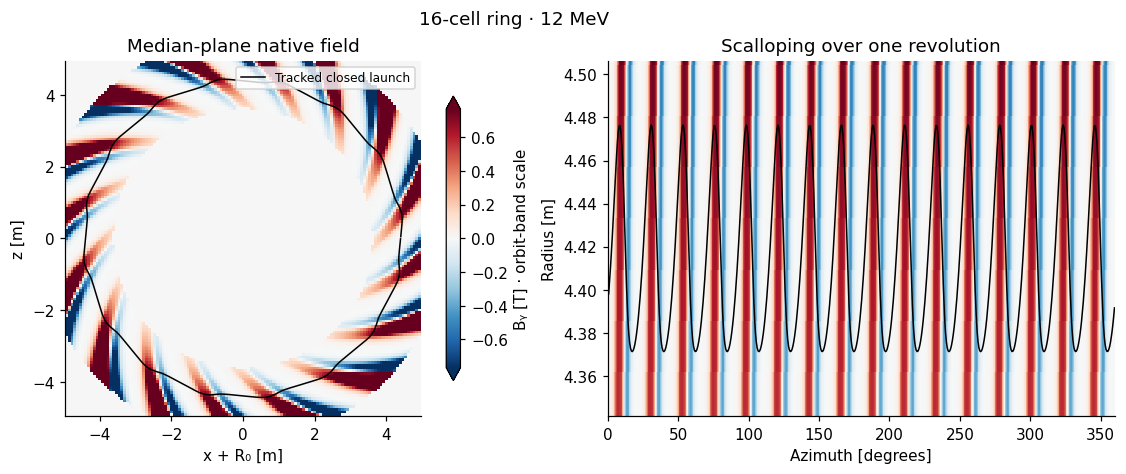

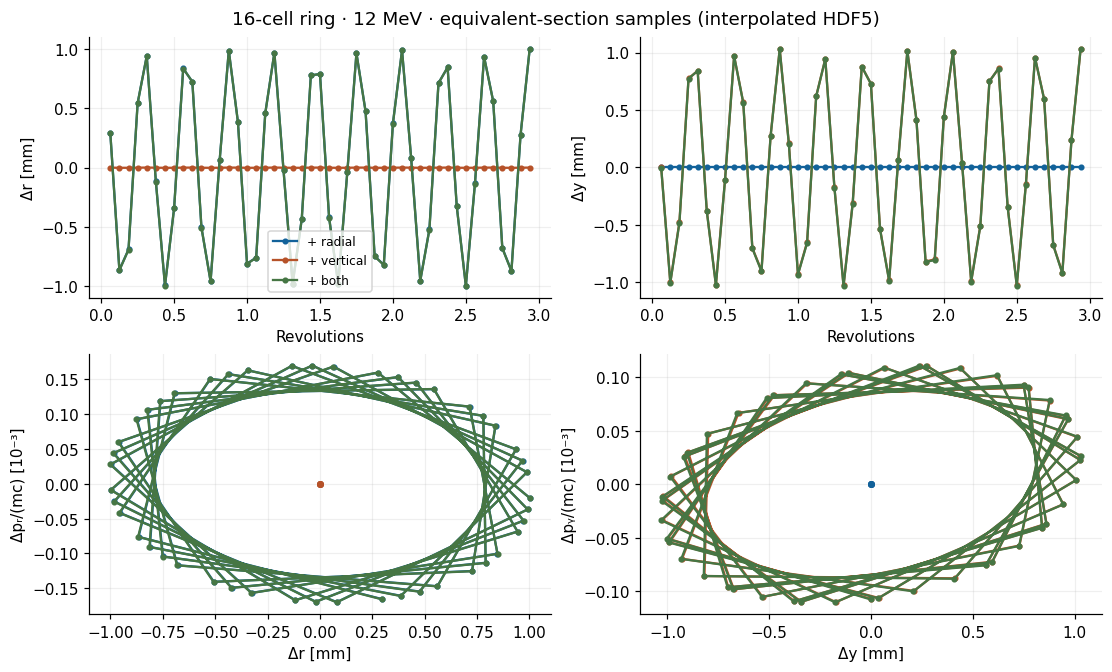

In [4]:
# DT, turns and output interval are read from this machine's input.
track_paths[case.key] = school.prepare_tracking(
    case, cof_results[case.key], SESSION / case.key / "track",
    displacement=DISPLACEMENT, maps=True)
school.execute(track_paths[case.key], EXE)
trajectories[case.key] = school.read_trajectories(case, track_paths[case.key])
data = trajectories[case.key]
relative_p_error = float(abs(data.p_norm_mc - case.p0).max() / case.p0)
assert data.row.nunique() == 8
assert relative_p_error < 1e-7
print(f"Snapshots: {data.frame.nunique()}, particles: {data.row.nunique()}, "
      f"maximum relative momentum-norm error: {relative_p_error:.2e}")
display(school.plot_fields_and_orbit(case, track_paths[case.key], data))
plt.close("all")
display(school.plot_oscillations(case, track_paths[case.key], data))
plt.close("all")

**Interpret:** relate the field pattern to the scalloping. Is a small radial
perturbation bounded? What happens in the vertical plane? Compare the combined
offset with the pure radial and vertical responses; their near overlap is
expected for small, approximately decoupled motion.

Three turns give a short illustration. More turns make denser phase portraits;
changing `DUMP_EVERY` changes interpolation resolution, not the native COF tunes.

## 3. Increase the spiral to 55° and switch D off

The reference radius, F strength, Enge coefficients, entrance positions and body
lengths are retained. The spiral faces change shape, and the D elements have
zero field while retaining their nominal arcs and apertures.

**Predict before running:** how might the orbit radius and vertical focusing
change? Two parameters change together here; this comparison alone does not
isolate the effect of spiral angle from the effect of switching D off.

This lesson reads **`school-55deg-d-off.in` itself**, including its own validated
finite-difference step. Inspect the differences from the first machine.

In [5]:
case = school.CASES[1]
display(FileLink(os.path.relpath(case.input_path)))
display(school.settings_table(case))
# Inspect the native solve before running it.
source = case.input_path.read_text()
print("ORBIT: COF" + source.split("ORBIT: COF", 1)[1].split(";", 1)[0] + ";")

/Users/adelmann/git/FFA25-school/opalx/school-55deg-d-off/school-55deg-d-off.in

,Parameter,Value
0,Input,school-55deg-d-off/school-55deg-d-off.in
1,Energy [MeV],12
2,R0 [m],4.42
3,Field index k,7.717022
4,Spiral [deg],55.0
5,Optical periods,16
6,COF integrator,DOP853
7,COF DT [ns],8.0
8,COF FDSTEP [m],0.0
9,COF MAXSTEPS,500000


ORBIT: COF, LINE=SCHOOL, BEAM=BEAM1, DT=COF_DT, TIMEINTEGRATOR="DOP853",
       MAXPATH=COF_MAXPATH, MAXSTEPS=COF_MAXSTEPS, X=COF_R_GUESS-R0, PX=COF_PR_GUESS, Y=COF_Y_GUESS, PY=COF_PY_GUESS,
       FDSTEP={COF_FDSTEP,COF_FDSTEP*BG,COF_FDSTEP,COF_FDSTEP*BG},
       SCALES={POSITION_SCALE,BG,POSITION_SCALE,BG}, XTOL=COF_XTOL, PTOL=COF_PTOL, MAXIT=COF_MAXIT, OUTPUT="orbit.json";


### Find the closed orbit and native full tunes

Run the variant and compare its launch radius and full tunes with the original.
The calculation uses a new result directory, not the previous machine's JSON.

In [6]:
cof_paths[case.key] = school.prepare_cof(case, SESSION / case.key / "cof")
school.execute(cof_paths[case.key], EXE)
cof_results[case.key] = school.read_cof(case, cof_paths[case.key])
print(school.native_report(cof_paths[case.key]))
display(school.results_table([(case, cof_results[case.key])]))

Running cof on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/55deg-d-off/cof/run.log
OPAL-X> Status=0 Closed orbit verified by a fresh map evaluation. evaluations=10
OPAL-X> Coordinates (x,px,y,py): -0.25673629772097328 0.017567795069157881 0 0 
OPAL-X> Residual: 4.9960036108132044e-15 1.7659484985443896e-15 0 0 
OPAL-X> One-turn eigenanalysis: STABLE (spectral test)
OPAL-X> Mode 1: fractional phase 0.1177400177205133, conjugate branch 0.8822599822794867
OPAL-X> Mode 2: fractional phase 0.1892098562460857, conjugate branch 0.8107901437539143
OPAL-X> Full tunes (uncoupled planar): horizontal/radial=3.1177400177205135 vertical=1.1892098562460856
OPAL-X> Phase samples=70 maximum phase step_rad=0.38126018579355503


,lattice,energy_MeV,radius_m,pr_mc,Qr,Qy,max_position_residual_m
0,55° spiral · D off,12.0,4.163264,0.017568,3.11774,1.18921,4.996004e-15


### Track and interpret

Repeat the same 1 mm displacement experiment with the new native closed state.
Compare the vertical motion and scalloping with the first machine.

Running track on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/55deg-d-off/track/run.log
Snapshots: 4557, particles: 8, maximum relative momentum-norm error: 1.13e-11


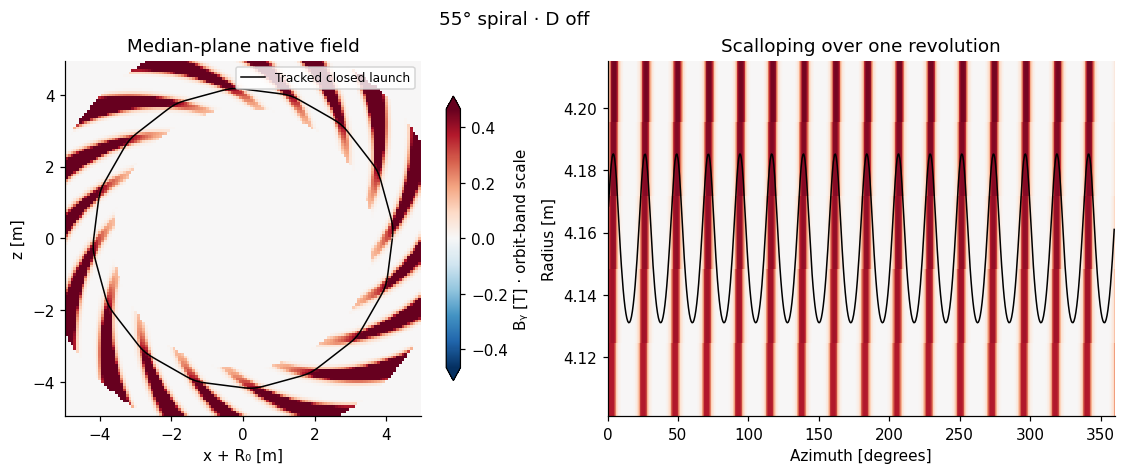

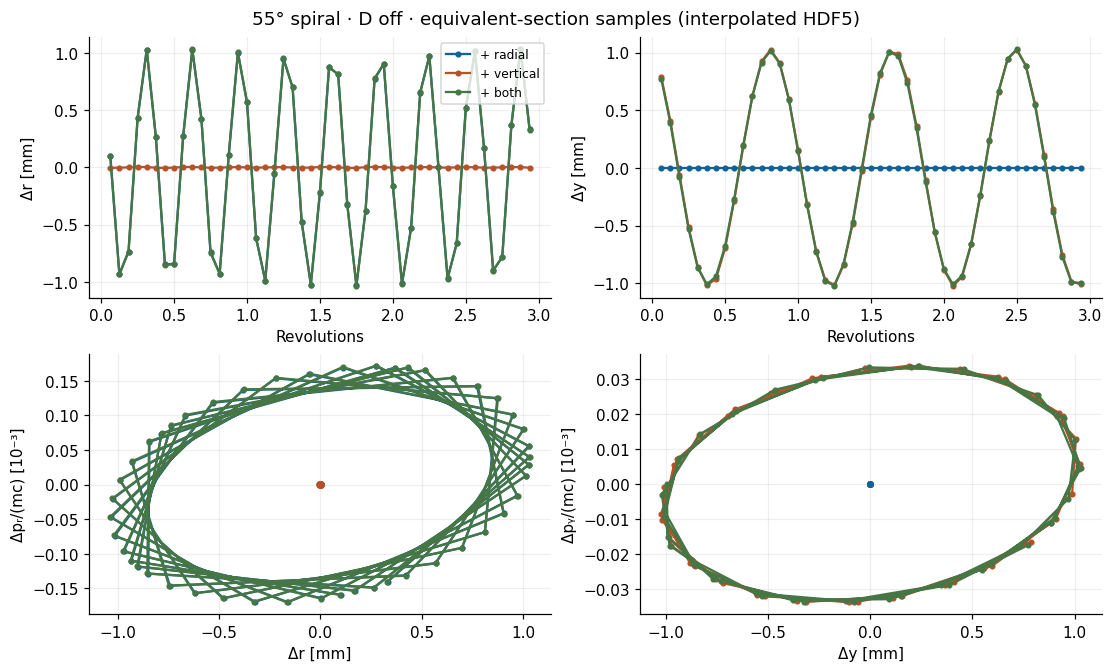

In [7]:
# DT, turns and output interval are read from this machine's input.
track_paths[case.key] = school.prepare_tracking(
    case, cof_results[case.key], SESSION / case.key / "track",
    displacement=DISPLACEMENT, maps=True)
school.execute(track_paths[case.key], EXE)
trajectories[case.key] = school.read_trajectories(case, track_paths[case.key])
data = trajectories[case.key]
relative_p_error = float(abs(data.p_norm_mc - case.p0).max() / case.p0)
assert data.row.nunique() == 8
assert relative_p_error < 1e-7
print(f"Snapshots: {data.frame.nunique()}, particles: {data.row.nunique()}, "
      f"maximum relative momentum-norm error: {relative_p_error:.2e}")
display(school.plot_fields_and_orbit(case, track_paths[case.key], data))
plt.close("all")
display(school.plot_oscillations(case, track_paths[case.key], data))
plt.close("all")

**Interpret:** which plane changes most in the native tune report? Does the
vertical trajectory support that qualitative change? Explain why removing
D's field does not require removing its nominal arc from the lattice.

## 4. Fourfold ring at 3 MeV

Four unequal F/D pairs form a 90° superperiod, repeated four times. Their
strengths and gaps differ. The ring has $R_0=4$ m, $k=7.4319$ and a 30° spiral.
It has sixteen F/D pairs but **four optical periods**.

**Inspect and predict:** find the four strength pairs and unequal gap constants
in the input. Why are neighbouring F/D pairs not equivalent sampling sections?
Use the full 90° superperiod to compare oscillations at equivalent locations.

In [8]:
case = school.CASES[2]
display(FileLink(os.path.relpath(case.input_path)))
display(school.settings_table(case))
# Inspect the native solve before running it.
source = case.input_path.read_text()
print("ORBIT: COF" + source.split("ORBIT: COF", 1)[1].split(";", 1)[0] + ";")

/Users/adelmann/git/FFA25-school/opalx/school-fourfold-3MeV/school-fourfold-3MeV.in

,Parameter,Value
0,Input,school-fourfold-3MeV/school-fourfold-3MeV.in
1,Energy [MeV],3
2,R0 [m],4.0
3,Field index k,7.4319
4,Spiral [deg],30.0
5,Optical periods,4
6,COF integrator,DOP853
7,COF DT [ns],8.0
8,COF FDSTEP [m],0.000001
9,COF MAXSTEPS,500000


ORBIT: COF, LINE=SCHOOL, BEAM=BEAM1, DT=COF_DT, TIMEINTEGRATOR="DOP853",
       MAXPATH=COF_MAXPATH, MAXSTEPS=COF_MAXSTEPS, X=COF_R_GUESS-R0, PX=COF_PR_GUESS, Y=COF_Y_GUESS, PY=COF_PY_GUESS,
       FDSTEP={COF_FDSTEP,COF_FDSTEP*BG,COF_FDSTEP,COF_FDSTEP*BG},
       SCALES={POSITION_SCALE,BG,POSITION_SCALE,BG}, XTOL=COF_XTOL, PTOL=COF_PTOL, MAXIT=COF_MAXIT, OUTPUT="orbit.json";


### Find the closed orbit and native full tunes

Native COF determines the full phase winding without requiring the optical
period count as input. Compare the resulting full tunes with the previous rings.

In [9]:
cof_paths[case.key] = school.prepare_cof(case, SESSION / case.key / "cof")
school.execute(cof_paths[case.key], EXE)
cof_results[case.key] = school.read_cof(case, cof_paths[case.key])
print(school.native_report(cof_paths[case.key]))
display(school.results_table([(case, cof_results[case.key])]))

Running cof on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/fourfold/cof/run.log
OPAL-X> Status=0 Closed orbit verified by a fresh map evaluation. evaluations=10
OPAL-X> Coordinates (x,px,y,py): -0.015031241051560507 0.0087047468374380592 0 0 
OPAL-X> Residual: -7.0445385635942159e-13 -9.738737594133795e-14 0 0 
OPAL-X> One-turn eigenanalysis: STABLE (spectral test)
OPAL-X> Mode 1: fractional phase 0.4388471270228142, conjugate branch 0.5611528729771857
OPAL-X> Mode 2: fractional phase 0.4473859590090479, conjugate branch 0.5526140409909521
OPAL-X> Full tunes (uncoupled planar): horizontal/radial=3.4473859590090479 vertical=3.438847127022814
OPAL-X> Phase samples=139 maximum phase step_rad=0.2914777465924927


,lattice,energy_MeV,radius_m,pr_mc,Qr,Qy,max_position_residual_m
0,Fourfold ring · 3 MeV,3.0,3.984969,0.008705,3.447386,3.438847,7.044539e-13


### Track and interpret the section plots

The following plot takes four equivalent-section samples per revolution.
That sampling aliases a full tune near 3.44 to about 0.55–0.56 apparent
oscillations per revolution. The slow wave therefore does not give the full
tune. Read the full tunes from native COF.

Running track on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/fourfold/track/run.log
Snapshots: 6996, particles: 8, maximum relative momentum-norm error: 2.60e-11


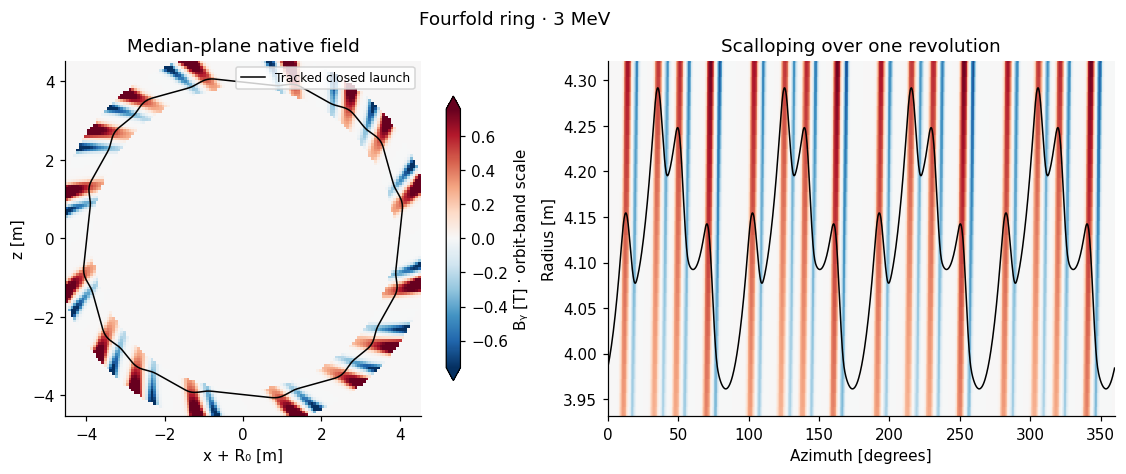

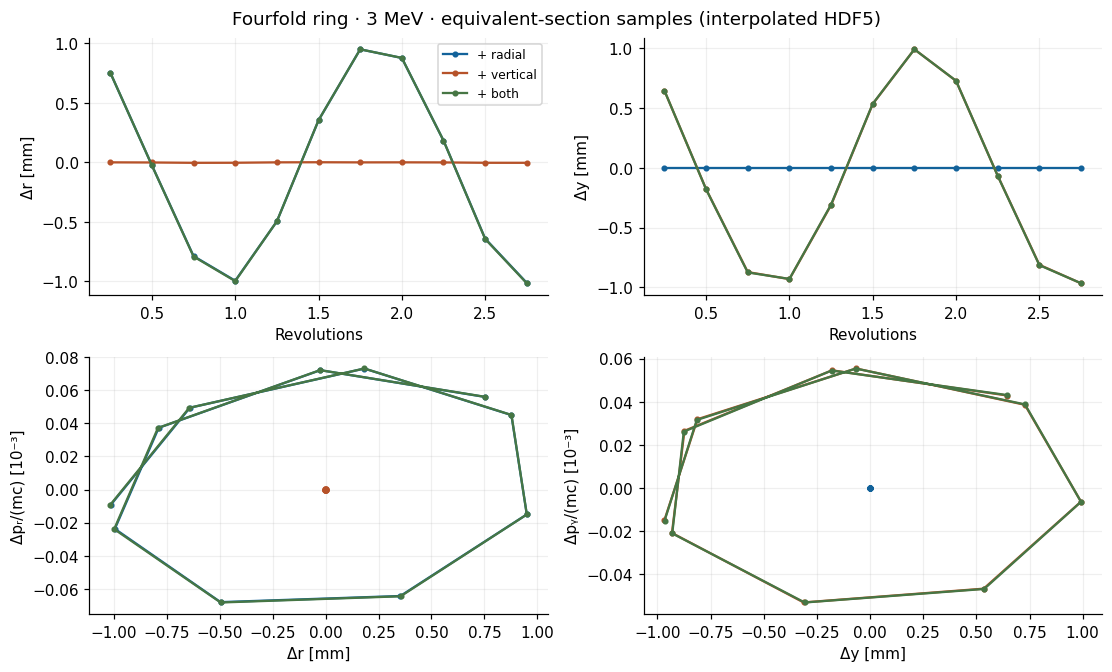

In [10]:
# DT, turns and output interval are read from this machine's input.
track_paths[case.key] = school.prepare_tracking(
    case, cof_results[case.key], SESSION / case.key / "track",
    displacement=DISPLACEMENT, maps=True)
school.execute(track_paths[case.key], EXE)
trajectories[case.key] = school.read_trajectories(case, track_paths[case.key])
data = trajectories[case.key]
relative_p_error = float(abs(data.p_norm_mc - case.p0).max() / case.p0)
assert data.row.nunique() == 8
assert relative_p_error < 1e-7
print(f"Snapshots: {data.frame.nunique()}, particles: {data.row.nunique()}, "
      f"maximum relative momentum-norm error: {relative_p_error:.2e}")
display(school.plot_fields_and_orbit(case, track_paths[case.key], data))
plt.close("all")
display(school.plot_oscillations(case, track_paths[case.key], data))
plt.close("all")

**Interpret:** identify the fourfold pattern in the field/orbit plot. Explain
why counting the slow oscillations in the section plot would give a misleading
tune even though the native optics is stable.

## 5. Compare the three machines

Compare the computed launch radii, radial momenta and full tunes. Which machine
has the weakest vertical focusing? Distinguish a changed reference radius
from a changed closed-orbit launch radius.

Approximate orientation checks are (3.41066, 3.39111), (3.11774, 1.18921), and
(3.44739, 3.43885). The table below is built from this session's native results,
not from those rounded checks or stored standalone JSON files.

In [11]:
summary = school.results_table([(c, cof_results[c.key]) for c in school.CASES])
display(summary)
summary.to_csv(SESSION / "native-cof-summary.csv", index=False)
print("This session's inputs and plots:", SESSION)
for c in school.CASES:
    display(FileLink(os.path.relpath(cof_paths[c.key] / "school.in")))
    display(FileLink(os.path.relpath(track_paths[c.key] / "fields-and-orbit.pdf")))

,lattice,energy_MeV,radius_m,pr_mc,Qr,Qy,max_position_residual_m
0,16-cell ring · 12 MeV,12.0,4.392926,0.016280,3.410660,3.391112,2.768272e-14
1,55° spiral · D off,12.0,4.163264,0.017568,3.117740,1.189210,4.996004e-15
2,Fourfold ring · 3 MeV,3.0,3.984969,0.008705,3.447386,3.438847,7.044539e-13


This session's inputs and plots: /Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99


/Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/16-cell/cof/school.in

/Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/16-cell/track/fields-and-orbit.pdf

/Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/55deg-d-off/cof/school.in

/Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/55deg-d-off/track/fields-and-orbit.pdf

/Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/fourfold/cof/school.in

/Users/adelmann/git/FFA25-school/opalx/runs/20261111T154118Z-f42a8f99/fourfold/track/fields-and-orbit.pdf

## 6. Further experiments

Make one change at a time and start a fresh session.

- **Orbit finding:** add `guess_offset=(1e-3, 1e-4, 1e-4, 1e-5)` to
  the `school.prepare_cof` call in a machine's solve cell.
  The offset applies to $(X,P_X,Y,P_Y)$. Observe native Newton convergence.
- **Numerical sensitivity:** halve that input's `COF_DT`, then separately its
  `COF_FDSTEP`; compare full tunes and residuals. Alternatively, use explicit
  `dt=` or `fd=` overrides in `prepare_cof`. Closure alone does not establish
  integration accuracy. Inspect stability diagnostics rather than relaxing
  their tolerances to obtain an answer.
- **Tracking:** halve `TRACK_DT` and `DUMP_EVERY` separately to distinguish
  transport error from plot interpolation. Set `NUM_TURNS` to 20 or 50 for denser
  portraits, then halve `DISPLACEMENT`. COF linear tunes do not replace a
  finite-amplitude frequency study.
- **Diagnostics, optional:** `school-16-cell-probe` is the same base magnetic
  machine with probe planes. It is a separate diagnostic example with its own
  launch and tracking settings; the core lessons do not require it. Its
  `particles.dat` is not automatically updated from this notebook's COF.

The helper reconstructs laboratory coordinates from native HDF5's moving
reference frame and checks particle identities and turn completion. Section
samples are interpolated and never used to estimate the reported tunes.
Native full-tune reporting here applies to stable, uncoupled planar rings.
The lessons do not establish second-order production-tracking tune convergence,
old-binary equivalence, collective or GPU behavior.

All generated JSON, logs, HDF5, tables and figures remain local under the fresh
session in `runs/`. The old OPAL notebook and its helpers are unchanged.